<>:41: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:41: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\santi\AppData\Local\Temp\ipykernel_6668\4053466065.py:41: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  plt.plot(x_prima, x, lw=2, label=f'$\lambda = {lmbda}$')


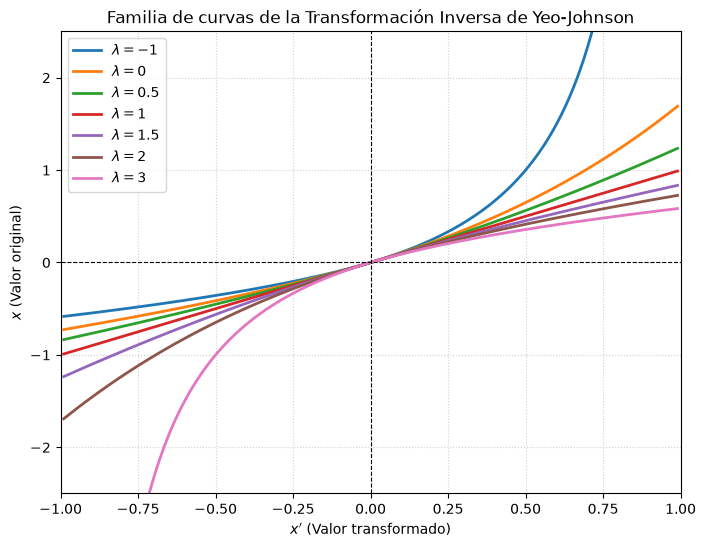

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def yeo_johnson_inversa(x_prima, lmbda):
    """
    Calcula la transformación inversa de Yeo-Johnson (obtiene x a partir de x' y lambda).
    Acepta tanto valores escalares como arreglos de NumPy.
    """
    x_prima = np.asarray(x_prima, dtype=float)
    x = np.zeros_like(x_prima)
    
    # máscaras booleanas para el dominio (x >= 0 equivale a x' >= 0)
    pos = x_prima >= 0
    neg = ~pos
    
    # Caso 1: x' >= 0
    if lmbda == 0:
        x[pos] = np.exp(x_prima[pos]) - 1
    else:
        x[pos] = np.power(lmbda * x_prima[pos] + 1, 1 / lmbda) - 1
        
    # Caso 2: x' < 0
    if lmbda == 2:
        x[neg] = 1 - np.exp(-x_prima[neg])
    else:
        x[neg] = 1 - np.power(-(2 - lmbda) * x_prima[neg] + 1, 1 / (2 - lmbda))
        
    return x

# 1. Definir el vector de valores en el intervalo abierto x' in (-1, 1)
x_prima = np.linspace(-0.99, 0.99, 500)

# 2. Definir distintos valores de lambda (incluyendo los casos especiales 0 y 2)
lambdas = [-1, 0, 0.5, 1, 1.5, 2, 3]

# 3. Graficar la familia de curvas
plt.figure(figsize=(8, 6))

for lmbda in lambdas:
    x = yeo_johnson_inversa(x_prima, lmbda)
    plt.plot(x_prima, x, lw=2, label=f'$\lambda = {lmbda}$')

plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Familia de curvas de la Transformación Inversa de Yeo-Johnson')
plt.xlabel("$x'$ (Valor transformado)")
plt.ylabel("$x$ (Valor original)")
plt.xlim(-1, 1)
plt.ylim(-2.5, 2.5)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()